# Problem 2 · 48-hour MVP
16-beat normalized chroma → shared Flow Matching → A/B/C/D → feasibility & fidelity.

Run from the repository root. Real audio is the default; synthetic smoke mode validates code only.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from src.data import prepare_dataset
from src.model import train_flow, sample
from src.constraints import project_simplex
from src.evaluation import evaluate, reference_bandwidth

SMOKE = False
SEED = 42
torch.set_num_threads(4)
OUT = Path('results/problem2/smoke' if SMOKE else 'results/problem2')
OUT.mkdir(parents=True, exist_ok=True)
config = dict(smoke=SMOKE, seed=SEED, train_steps=10 if SMOKE else 3000,
              batch_size=32 if SMOKE else 256, ode_steps=10 if SMOKE else 100,
              alpha=0.1, hidden=128, lr=1e-3, max_eval=512)


## 1. Data · member A
Load the prepared MAESTRO official-split arrays. See `data/problem2/PERSON_A_HANDOFF.md`. Rebuild after changes with `python scripts/prepare_person_a.py`. Synthetic mode only validates code.

In [2]:
if SMOKE:
    rng = np.random.default_rng(SEED)
    train = rng.dirichlet(np.ones(12), size=(64,16)).astype('float32')
    test = rng.dirichlet(np.ones(12), size=(32,16)).astype('float32')
else:
    # Person A has prepared official-split data. Rebuild with scripts/prepare_person_a.py after audio/code changes.
    processed = Path('data/problem2/processed')
    manifest = json.loads((processed/'manifest.json').read_text())
    assert manifest['version'] == 2 and 'official' in manifest['split_policy']
    import hashlib
    assert hashlib.sha256(Path('src/data.py').read_bytes()).hexdigest() == manifest['preprocessing_sha256'], 'Preprocessing changed; rebuild Person A data'
    assert hashlib.sha256(Path('data/problem2/sources.json').read_bytes()).hexdigest() == manifest['source_manifest_sha256'], 'Source list changed; rebuild Person A data'
    train, test = np.load(processed/'train.npy'), np.load(processed/'test.npy')
print('Train / test:', train.shape, test.shape)
assert np.allclose(train.sum(-1),1,atol=1e-5) and (train>=0).all()

assert test.dtype == train.dtype == np.float32
assert np.isfinite(test).all() and np.isfinite(train).all()
assert (test >= 0).all() and np.allclose(test.sum(-1), 1, atol=1e-5)


Train / test: (1129, 16, 12) (297, 16, 12)


## 2. Train once · member B
Same architecture/objective as Problem 1 with 192-dimensional input/output. No torus weights are overwritten.

In [3]:
model, losses = train_flow(train, steps=config['train_steps'], batch_size=config['batch_size'], seed=SEED)
checkpoint = OUT/'flow.pt' if SMOKE else Path('models/problem2/flow.pt')
checkpoint.parent.mkdir(parents=True, exist_ok=True)
torch.save(dict(state_dict=model.state_dict(), config=config), checkpoint)


## 3. Shared-noise A/B/C/D
B uses a fixed per-step alpha of 0.1. Euclidean projection is applied separately to every beat.

In [4]:
n = min(config['max_eval'], len(test))
indices = np.random.default_rng(SEED+1).permutation(len(test))[:n]
reference = test[indices]
noise = torch.randn(n,16,12, generator=torch.Generator().manual_seed(SEED+2))
samples = {m: sample(model, noise, m, steps=config['ode_steps'], alpha=config['alpha']) for m in 'ABCD'}
assert torch.allclose(samples['D'],project_simplex(samples['A']),atol=1e-6)
np.savez(OUT/'samples.npz', reference=reference, reference_indices=indices, noise=noise.numpy(),
         **{m:x.numpy() for m,x in samples.items()})


## 4. Evaluate · member C
MMD² uses the same reference and bandwidth across all methods. Smaller temporal differences are descriptive, not proof of musical quality.

In [5]:
bandwidth = reference_bandwidth(reference)
metrics = pd.DataFrame({m:evaluate(x,reference,bandwidth) for m,x in samples.items()}).T
metrics.to_csv(OUT/'metrics.csv')
config.update(bandwidth_squared=bandwidth, n_train=len(train), n_test=len(test), n_eval=n,
              torch_version=torch.__version__, numpy_version=np.__version__)
(OUT/'config.json').write_text(json.dumps(config,indent=2))
display(metrics)


,negative_mass_mean,sum_error_mean,sum_error_max,feasible_beats,feasible_sequences,mmd2,beat_l2_mean,beat_l2_std,beat_l2_p95,beat_l2_mean_gap
A,2.778106,1.470250e+00,7.326403e+00,0.0,0.0,0.605088,3.008453,0.654257,4.110336,2.713527
B,0.021879,6.083874e-02,2.462692e-01,0.0,0.0,0.055160,0.532830,0.130549,0.748241,0.237903
C,0.000000,3.053045e-08,8.940697e-08,1.0,1.0,0.046743,0.480945,0.118806,0.677352,0.186019
D,0.000000,6.175617e-08,3.576279e-07,1.0,1.0,0.187726,0.847432,0.238159,1.207221,0.552505


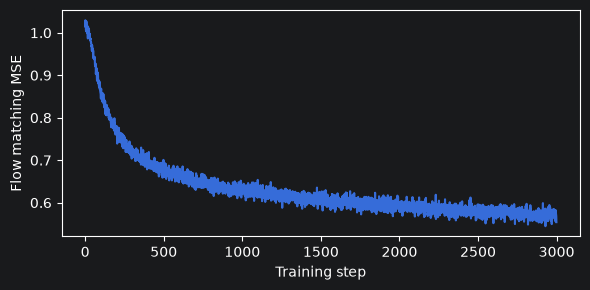

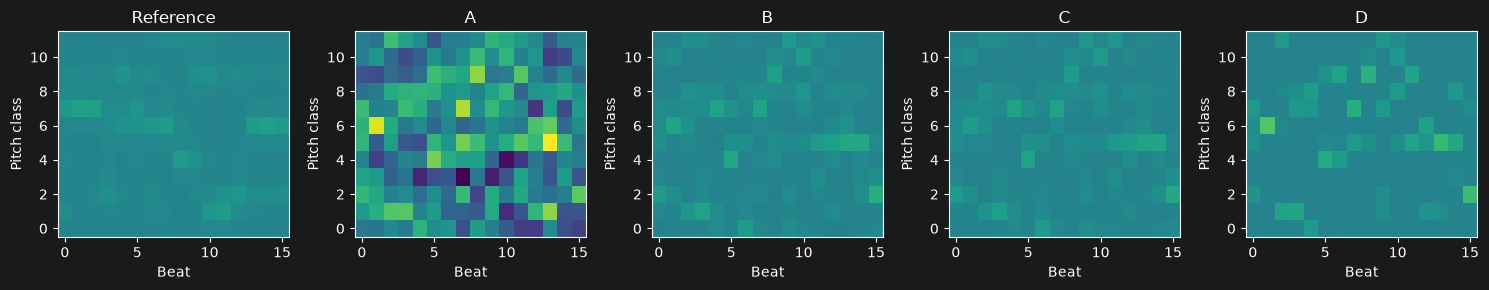

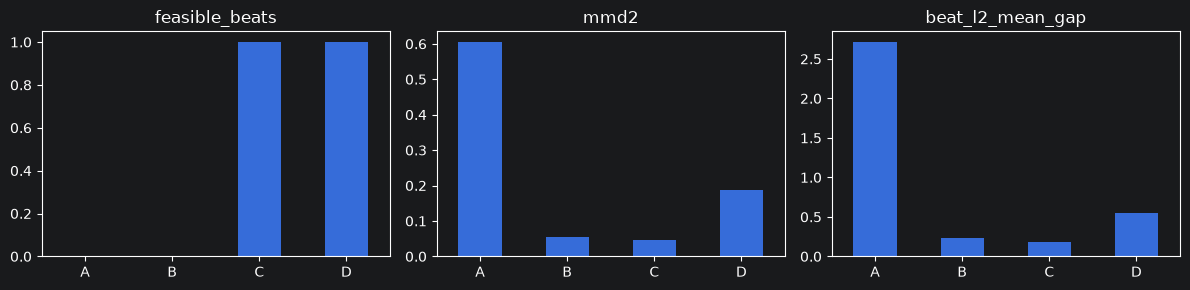

REAL_EXPERIMENT_OK


In [6]:
fig, ax = plt.subplots(figsize=(6,3))
ax.plot(losses); ax.set(xlabel='Training step',ylabel='Flow matching MSE')
fig.tight_layout(); fig.savefig(OUT/'training.png',dpi=140); plt.show()

fig, axes = plt.subplots(1,5,figsize=(15,3))
views = {'Reference':reference[0], **{m:x[0].numpy() for m,x in samples.items()}}
vmin = min(x.min() for x in views.values()); vmax = max(x.max() for x in views.values())
for ax,(name,x) in zip(axes,views.items()):
    ax.imshow(x.T,origin='lower',aspect='auto',vmin=vmin,vmax=vmax)
    ax.set(title=name,xlabel='Beat',ylabel='Pitch class')
fig.tight_layout(); fig.savefig(OUT/'chroma.png',dpi=140); plt.show()

fig, axes = plt.subplots(1,3,figsize=(12,3))
for ax,column in zip(axes,['feasible_beats','mmd2','beat_l2_mean_gap']):
    metrics[column].plot.bar(ax=ax,rot=0); ax.set_title(column)
fig.tight_layout(); fig.savefig(OUT/'comparison.png',dpi=140); plt.show()
print('SMOKE_ONLY_OK' if SMOKE else 'REAL_EXPERIMENT_OK')


## Discussion checklist
- Did enforcing the simplex improve feasibility at a fidelity cost? Use the measured values.
- Compare C and D without assuming a winner.
- Report song/window counts, data sources, skipped files and single-training-run limitation.
- Future work: more datasets, seeds, harmonic continuity and listening evaluation.
- Simplex feasibility alone does not establish musical structure.